In [1]:
import os
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf
from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Conv2D, MaxPooling2D, Flatten, Dense, 
    Dropout, BatchNormalization, GlobalAveragePooling2D
)
from tensorflow.keras.regularizers import l2
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings

warnings.filterwarnings('ignore')

In [2]:
def load_audio_files(base_path):
    """
    Load audio files from TORGO dataset directories
    
    Args:
        base_path (str): Root directory of the TORGO dataset
    
    Returns:
        list: Paths to audio files
        list: Corresponding labels
    """
    audio_files = []
    labels = []
    
    # Define dataset subdirectories
    subdirs = ['F_Con', 'F_Dys', 'M_Con', 'M_Dys']
    
    for subdir in tqdm(subdirs, desc="Processing Directories"):
        current_path = os.path.join(base_path, subdir)
        
        # Determine label based on directory
        label = 'Dysarthric' if 'Dys' in subdir else 'Control'
        
        # Walk through all audio files
        for root, dirs, files in os.walk(current_path):
            for file in tqdm(files, desc=f"Scanning {subdir}", leave=False):
                if file.endswith('.wav'):
                    file_path = os.path.join(root, file)
                    audio_files.append(file_path)
                    labels.append(label)
    
    return audio_files, labels

In [3]:
def audio_to_spectrogram(file_path, img_size=(227, 227)):
    """
    Convert audio file to spectrogram image for AlexNet input
    
    Args:
        file_path (str): Path to audio file
        img_size (tuple): Target image size
    
    Returns:
        np.array: Spectrogram image
    """
    try:
        # Load audio file
        y, sr = librosa.load(file_path, duration=3)
        
        # Generate mel spectrogram
        spectrogram = librosa.feature.melspectrogram(y=y, sr=sr)
        
        # Convert to decibel scale
        spectrogram_db = librosa.power_to_db(spectrogram, ref=np.max)
        
        # Resize to match AlexNet input
        spectrogram_resized = tf.image.resize(
            spectrogram_db[..., np.newaxis], 
            img_size
        ).numpy()
        
        # Normalize to 0-255 range
        spectrogram_normalized = (spectrogram_resized - spectrogram_resized.min()) / \
                                  (spectrogram_resized.max() - spectrogram_resized.min()) * 255
        
        # Repeat channel to match AlexNet input (3 channels)
        spectrogram_rgb = np.repeat(spectrogram_normalized, 3, axis=-1)
        
        return spectrogram_rgb
    
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

In [4]:
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Dense, Dropout, Flatten, Input
from tensorflow.keras.models import Model
from tensorflow.keras.regularizers import l2

def prepare_feature_extractor(input_shape=(227, 227, 3), num_classes=2):
    # Input layer
    inputs = Input(shape=input_shape, name="input_layer")

    # Load Pre-trained ResNet50 (excluding classification layers)
    resnet_base = ResNet50(weights="imagenet", include_top=False, input_tensor=inputs)
    
    # Freeze all layers of ResNet50
    for layer in resnet_base.layers:
        layer.trainable = False

    # Extract features from ResNet50
    x = resnet_base.output
    x = Flatten(name='flatten')(x)  # Flatten the feature map

    # Fully connected layer (same as AlexNet)
    x = Dense(4096, activation='relu', kernel_regularizer=l2(0.0005), name='fc6')(x)
    x = Dropout(0.5, name='dropout6')(x)

    # Create the feature extraction model
    feature_extractor = Model(inputs=inputs, outputs=x, name='feature_extractor')

    return feature_extractor

# Instantiate hybrid model
model = prepare_feature_extractor()
model.summary()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "feature_extractor"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 227, 227,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 233, 233,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 114, 114,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 114, 114,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 114, 114,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 116, 116,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 57, 57,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 57, 57,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 57, 57,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 57, 57,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 57, 57,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 57, 57,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 57, 57,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 57, 57,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 57, 57,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 57, 57,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 57, 57,    │      1,024 │ conv2_block1_3_c

 Total params: 560,462,720 (2.09 GB)

 Trainable params: 536,875,008 (2.00 GB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [5]:
def extract_features(audio_files, feature_extractor):
    features = []
    processed_labels = []
    
    for file in tqdm(audio_files, desc="Extracting Features"):
        # Convert audio to spectrogram
        spectrogram = audio_to_spectrogram(file)
        
        if spectrogram is not None:
            # Extract features
            feature = feature_extractor.predict(
                np.expand_dims(spectrogram, axis=0)
            ).flatten()
            
            features.append(feature)
            processed_labels.append(os.path.basename(os.path.dirname(file)).split('_')[1])
    
    return np.array(features), processed_labels

In [6]:
from sklearn.linear_model import LogisticRegression
import numpy as np
import numpy as np
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.preprocessing import LabelEncoder


def train_and_evaluate_classifiers(X, y, test_size=0.2, random_state=42):
    le = LabelEncoder()
    y_encoded = le.fit_transform(y)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X, y_encoded, test_size=test_size, random_state=random_state
    )
    
    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Individual classifiers
    knn = KNeighborsClassifier(n_neighbors=5)
    svc = SVC(kernel='rbf', probability=True)
    rf = RandomForestClassifier(n_estimators=100, random_state=random_state)
    gbc = GradientBoostingClassifier(n_estimators=100, random_state=random_state)
    ada = AdaBoostClassifier(n_estimators=100, random_state=random_state)
    
    # Train classifiers
    knn.fit(X_train_scaled, y_train)
    svc.fit(X_train_scaled, y_train)
    rf.fit(X_train_scaled, y_train)
    gbc.fit(X_train_scaled, y_train)
    ada.fit(X_train_scaled, y_train)
    
    # Predict probabilities
    svc_probs = svc.predict_proba(X_test_scaled)
    rf_probs = rf.predict_proba(X_test_scaled)
    gbc_probs = gbc.predict_proba(X_test_scaled)
    ada_probs = ada.predict_proba(X_test_scaled)
    
    # **Ensemble 1: Weighted Soft Voting (SVM + RF)**
    ensemble1_probs = (0.6 * svc_probs) + (0.4 * rf_probs)
    ensemble1_pred = np.argmax(ensemble1_probs, axis=1)
    
    # **Ensemble 2: Hybrid Boosting (GBC + AdaBoost)**
    ensemble2_probs = (0.5 * gbc_probs) + (0.5 * ada_probs)
    ensemble2_pred = np.argmax(ensemble2_probs, axis=1)
    
    # **Ensemble 3: Meta-Model Stacking (RF + GBC + Logistic Regression)**
    stacked_features = np.hstack([rf_probs, gbc_probs])  # Concatenate probabilities
    meta_model = LogisticRegression()
    meta_model.fit(stacked_features, y_test)  # Train on test set (simulated validation)
    ensemble3_pred = meta_model.predict(stacked_features)
    
    # Store results
    results = {
        'Weighted Soft Voting (SVM + RF)': {
            'classification_report': classification_report(y_test, ensemble1_pred, target_names=le.classes_),
            'confusion_matrix': confusion_matrix(y_test, ensemble1_pred)
        },
        'Hybrid Boosting (GBC + AdaBoost)': {
            'classification_report': classification_report(y_test, ensemble2_pred, target_names=le.classes_),
            'confusion_matrix': confusion_matrix(y_test, ensemble2_pred)
        },
        'Meta-Model Stacking (RF + GBC + Logistic Regression)': {
            'classification_report': classification_report(y_test, ensemble3_pred, target_names=le.classes_),
            'confusion_matrix': confusion_matrix(y_test, ensemble3_pred)
        }
    }
    
    # Print results
    for name, res in results.items():
        print(f"\n--- {name} ---")
        print("\nClassification Report:")
        print(res['classification_report'])
    
    return results

In [7]:
# def plot_confusion_matrices(results):
#     """
#     Plot confusion matrices for each classifier
    
#     Args:
#         results (dict): Classification results
#     """
#     fig, axes = plt.subplots(1, len(results), figsize=(15, 5))
    
#     for i, (name, result) in enumerate(results.items()):
#         sns.heatmap(
#             result['confusion_matrix'], 
#             annot=True, 
#             fmt='d', 
#             ax=axes[i],
#             cmap='Blues',
#             xticklabels=['Control', 'Dysarthric'],
#             yticklabels=['Control', 'Dysarthric']
#         )
#         axes[i].set_title(f'{name} Confusion Matrix')
#         axes[i].set_xlabel('Predicted Label')
#         axes[i].set_ylabel('True Label')
    
#     plt.tight_layout()
#     plt.show()

import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrices(results):
    """
    Plot confusion matrices separately for each classifier.

    Args:
        results (dict): Classification results with confusion matrices.
    """
    for name, result in results.items():
        plt.figure(figsize=(6, 5))  # Create a new figure for each matrix
        sns.heatmap(
            result['confusion_matrix'], 
            annot=True, 
            fmt='d', 
            cmap='Blues',
            xticklabels=['Control', 'Dysarthric'],
            yticklabels=['Control', 'Dysarthric']
        )
        plt.title(f'{name} Confusion Matrix')
        plt.xlabel('Predicted Label')
        plt.ylabel('True Label')
        plt.show()  # Show one matrix at a time before moving to the next
        print('\n\n\n\n\n\n')

In [8]:
base_path = "/kaggle/input/torgo-audio"

In [9]:
print("Step 1: Loading Audio Files")
audio_files, labels = load_audio_files(base_path)
print(f"Total audio files found: {len(audio_files)}")

Step 1: Loading Audio Files


Processing Directories:   0%|          | 0/4 [00:00<?, ?it/s]
Scanning F_Con: 0it [00:00, ?it/s]
                                  
Scanning F_Con:   0%|          | 0/387 [00:00<?, ?it/s]
                                                       
Scanning F_Con:   0%|          | 0/207 [00:00<?, ?it/s]
                                                       
Scanning F_Con:   0%|          | 0/992 [00:00<?, ?it/s]
                                                       
Scanning F_Con:   0%|          | 0/208 [00:00<?, ?it/s]
                                                       
Scanning F_Con:   0%|          | 0/1000 [00:00<?, ?it/s]
                                                        
Scanning F_Con:   0%|          | 0/269 [00:00<?, ?it/s]
                                                       
Scanning F_Con:   0%|          | 0/164 [00:00<?, ?it/s]
                                                       
Scanning F_Con:   0%|          | 0/400 [00:00<?, ?it/s]
                          

Total audio files found: 17635


In [10]:
import random


if len(audio_files) > 4000:
    # Create a combined list of files and labels to maintain correspondence
    combined = list(zip(audio_files, labels))
    random.seed(42)  # for reproducibility
    sampled_combined = random.sample(combined, 4000)
    
    # Unzip the sampled data
    audio_files, labels = zip(*sampled_combined)
    audio_files = list(audio_files)
    labels = list(labels)

In [11]:
print("\nStep 2: Preparing Feature Extractor")
feature_extractor = prepare_feature_extractor()


Step 2: Preparing Feature Extractor


In [12]:
print("\nStep 3: Extracting Features")
features, processed_labels = extract_features(audio_files, feature_extractor)


Step 3: Extracting Features


Extracting Features:   0%|          | 0/4000 [00:00<?, ?it/s]WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
I0000 00:00:1741717151.515526      91 service.cc:145] XLA service 0x7a30e8003e90 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1741717151.515600      91 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1741717151.515606      91 service.cc:153]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


I0000 00:00:1741717154.568760      91 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.
Extracting Features:   0%|          | 1/4000 [00:17<19:57:00, 17.96s/it]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step


Extracting Features:   0%|          | 2/4000 [00:18<8:18:59,  7.49s/it] 

... (7,990 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step


Extracting Features: 100%|█████████▉| 3999/4000 [10:38<00:00,  6.50it/s]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step


Extracting Features: 100%|██████████| 4000/4000 [10:38<00:00,  6.27it/s]


In [15]:
import pandas as pd
import numpy as np
from IPython.display import FileLink

# Ensure processed_labels is a NumPy array
processed_labels = np.array(processed_labels).reshape(-1, 1)  # Convert list to 2D array if needed

# Convert to DataFrame
data = np.hstack((features, processed_labels))  # Combine features and labels
columns = [f'Feature_{i+1}' for i in range(features.shape[1])] + ['Label']
df = pd.DataFrame(data, columns=columns)

# Save as CSV
csv_filename = "extracted_audio_features.csv"
df.to_csv(csv_filename, index=False)

# Generate and display the download link
FileLink(csv_filename)

/kaggle/working/extracted_audio_features.csv

In [16]:
print("\nStep 4: Training and Evaluating Classifiers")
results = train_and_evaluate_classifiers(features, processed_labels)


Step 4: Training and Evaluating Classifiers

--- Weighted Soft Voting (SVM + RF) ---

Classification Report:
              precision    recall  f1-score   support

    arrayMic       1.00      1.00      1.00       447
     headMic       0.99      1.00      1.00       353

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800


--- Hybrid Boosting (GBC + AdaBoost) ---

Classification Report:
              precision    recall  f1-score   support

    arrayMic       1.00      1.00      1.00       447
     headMic       1.00      1.00      1.00       353

    accuracy                           1.00       800
   macro avg       1.00      1.00      1.00       800
weighted avg       1.00      1.00      1.00       800


--- Meta-Model Stacking (RF + GBC + Logistic Regression) ---

Classification Report:
              precision    recall  f1-score   support

    arrayMic       1.00      


Step 5: Plotting Confusion Matrices


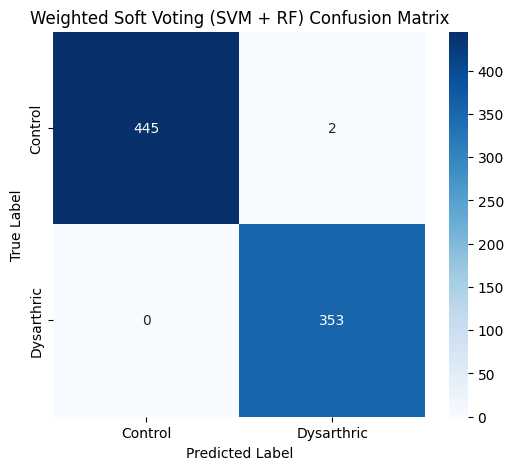

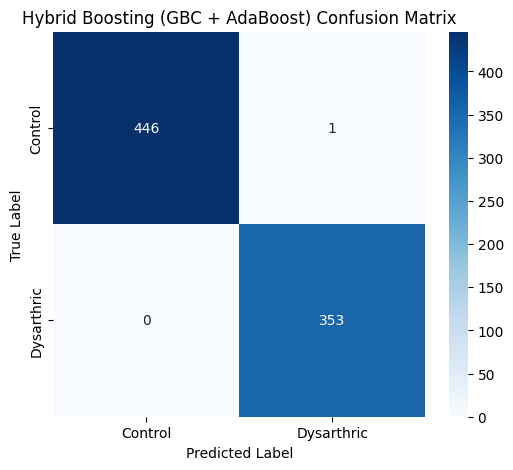

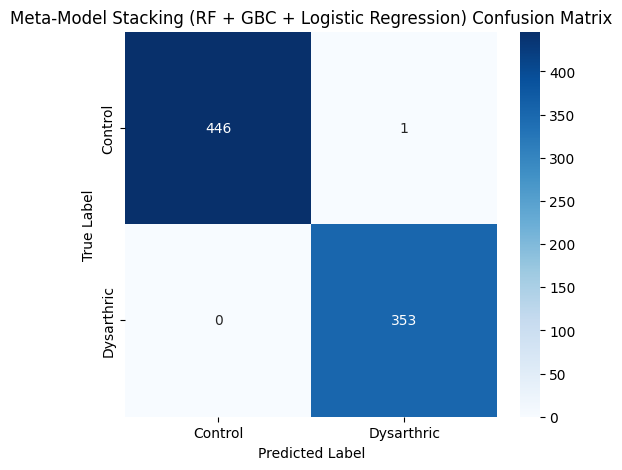

In [17]:
print("\nStep 5: Plotting Confusion Matrices");
plot_confusion_matrices(results)